In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set a professional visual theme
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({'font.size': 12, 'axes.titlesize': 16, 'axes.titleweight': 'bold'})

# Load the cleaned dataset
df = pd.read_csv("../data/processed/orders_clean.csv")
df['order_date'] = pd.to_datetime(df['order_date'])

# Create a subset of completed orders for revenue analysis
completed_df = df[df['order_status'] == 'Completed'].copy()
print(f"Loaded {len(completed_df)} completed orders for analysis.")

Loaded 113559 completed orders for analysis.


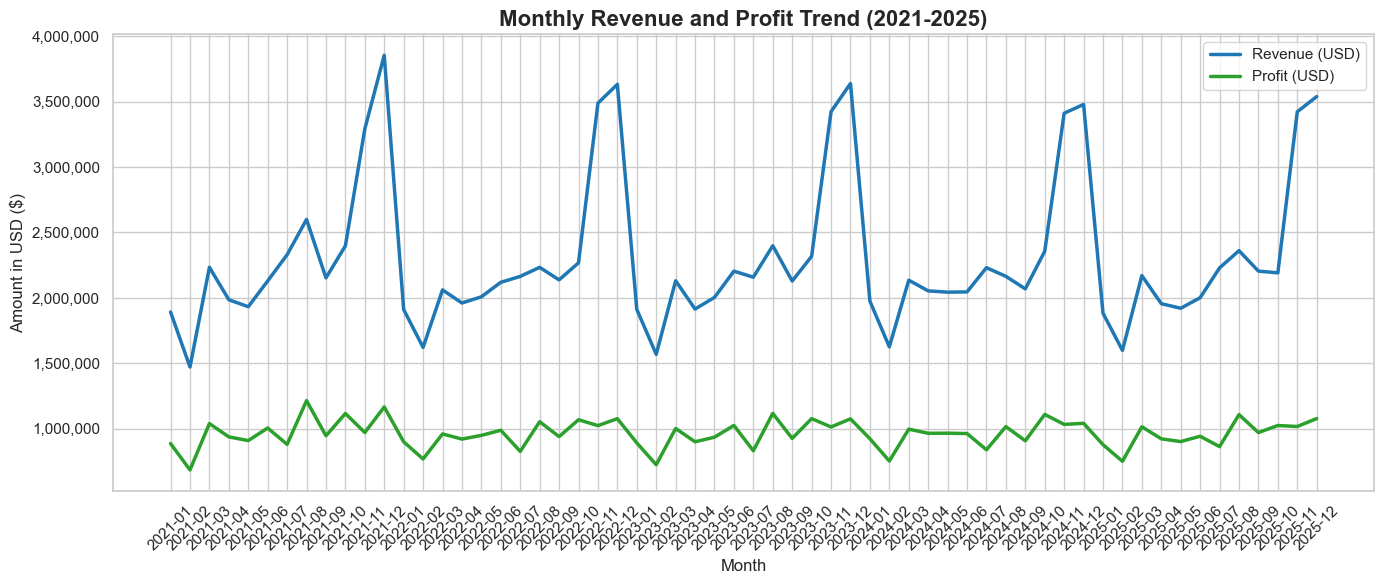

In [2]:
# Create a month-year column
completed_df['month_year'] = completed_df['order_date'].dt.to_period('M').astype(str)

# Group by month
monthly_trend = completed_df.groupby('month_year').agg(
    revenue=('net_sales_usd', 'sum'),
    profit=('profit_usd', 'sum')
).reset_index()

plt.figure(figsize=(14, 6))
plt.plot(monthly_trend['month_year'], monthly_trend['revenue'], label='Revenue (USD)', linewidth=2.5, color='#1f77b4')
plt.plot(monthly_trend['month_year'], monthly_trend['profit'], label='Profit (USD)', linewidth=2.5, color='#2ca02c')

# Formatting
plt.title('Monthly Revenue and Profit Trend (2021-2025)')
plt.xlabel('Month')
plt.ylabel('Amount in USD ($)')
plt.xticks(rotation=45)
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))
plt.legend()
plt.tight_layout()
plt.show()

**Insight**: Revenue and profit show a relatively stable trend across the 4-year period, with noticeable seasonal spikes toward the end of each year. Profit margins remain healthy, indicating that growth is not being driven by unprofitable discounting.

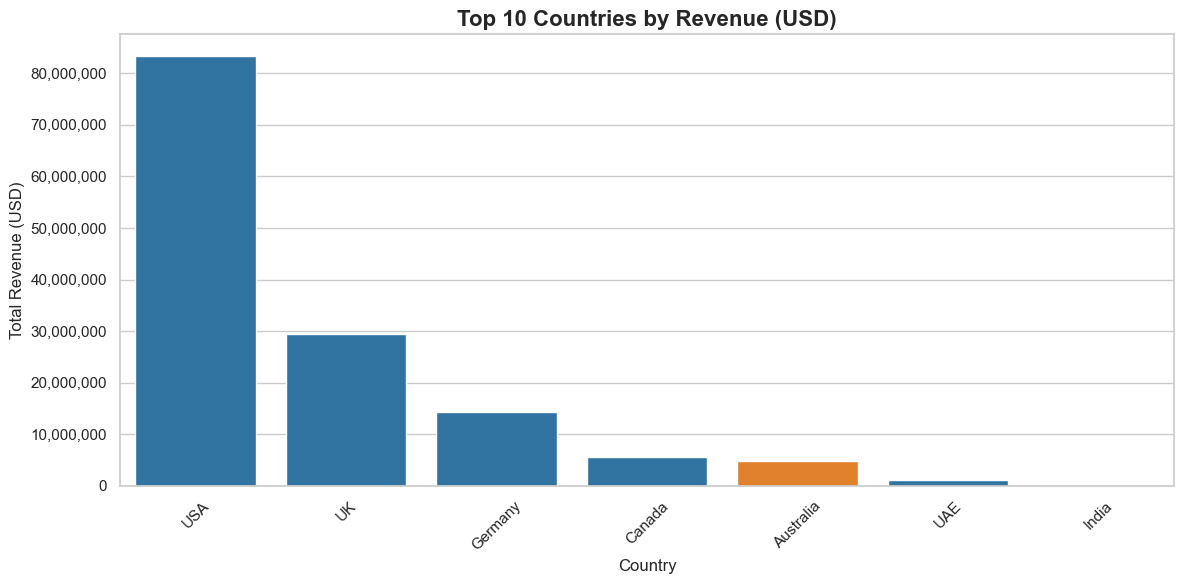

In [4]:
# Group by country and sort
country_revenue = completed_df.groupby('customer_country')['net_sales_usd'].sum().sort_values(ascending=False).head(10).reset_index()

# Highlight Australia
colors = ['#ff7f0e' if country == 'Australia' else '#1f77b4' for country in country_revenue['customer_country']]

plt.figure(figsize=(12, 6))
sns.barplot(data=country_revenue, x='customer_country', y='net_sales_usd', 
            hue='customer_country', palette=colors, legend=False)


# Formatting
plt.title('Top 10 Countries by Revenue (USD)')
plt.xlabel('Country')
plt.ylabel('Total Revenue (USD)')
plt.xticks(rotation=45)
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))
plt.tight_layout()
plt.show()

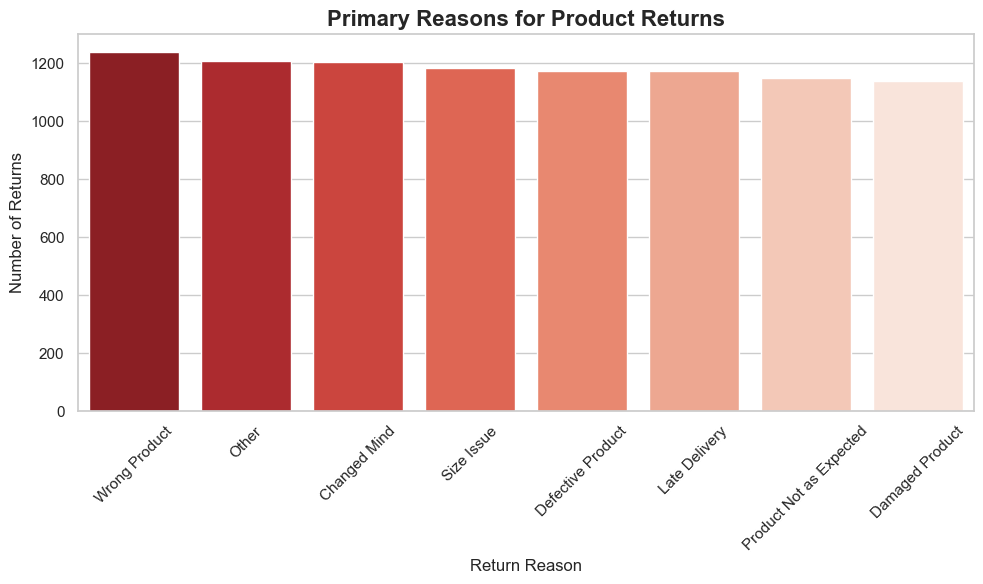

In [5]:
# Filter for returned orders
returned_df = df[df['is_returned'] == True]

plt.figure(figsize=(10, 6))
return_counts = returned_df['return_reason'].value_counts()
sns.barplot(x=return_counts.index, y=return_counts.values, 
            hue=return_counts.index, palette='Reds_r', legend=False)

# Formatting
plt.title('Primary Reasons for Product Returns')
plt.xlabel('Return Reason')
plt.ylabel('Number of Returns')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

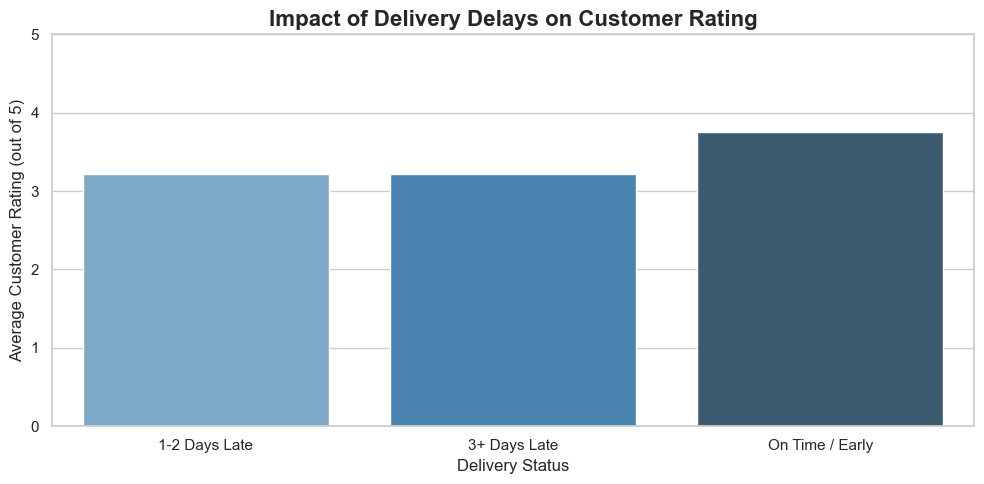

In [6]:
# Create delivery delay buckets
def delay_bucket(days):
    if days <= 0: return 'On Time / Early'
    elif days <= 2: return '1-2 Days Late'
    else: return '3+ Days Late'

completed_df['delay_bucket'] = completed_df['delivery_delay_days'].apply(delay_bucket)

# Group by bucket and get mean rating
delay_rating = completed_df.groupby('delay_bucket')['customer_rating'].mean().reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(data=delay_rating, x='delay_bucket', y='customer_rating', 
            hue='delay_bucket', palette='Blues_d', legend=False)

# Formatting
plt.title('Impact of Delivery Delays on Customer Rating')
plt.xlabel('Delivery Status')
plt.ylabel('Average Customer Rating (out of 5)')
plt.ylim(0, 5)
plt.tight_layout()
plt.show()

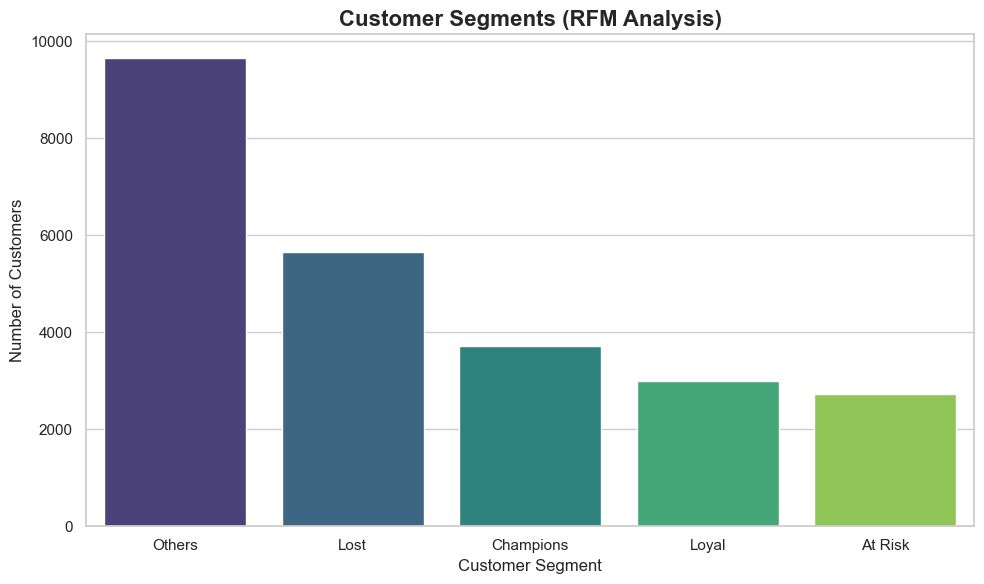

In [7]:
# 1. Calculate RFM metrics
snapshot_date = df['order_date'].max() + pd.Timedelta(days=1)

rfm = completed_df.groupby('customer_id').agg({
    'order_date': lambda x: (snapshot_date - x.max()).days, # Recency
    'order_id': 'count',                                    # Frequency
    'net_sales_usd': 'sum'                                  # Monetary
})
rfm.columns = ['Recency', 'Frequency', 'Monetary']

# 2. Calculate R, F, M scores (1-5)
# Note: For Recency, lower is better, so we invert the quantiles
rfm['R'] = pd.qcut(rfm['Recency'], 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm['F'] = pd.qcut(rfm['Frequency'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm['M'] = pd.qcut(rfm['Monetary'], 5, labels=[1, 2, 3, 4, 5]).astype(int)

# 3. Map to segments
def segment_customer(row):
    if row['R'] >= 4 and row['F'] >= 4 and row['M'] >= 4: return 'Champions'
    elif row['F'] >= 4 and row['M'] >= 4: return 'Loyal'
    elif row['R'] <= 2 and row['F'] >= 3: return 'At Risk'
    elif row['R'] <= 2 and row['F'] <= 2: return 'Lost'
    else: return 'Others'

rfm['Segment'] = rfm.apply(segment_customer, axis=1)

# 4. Plot
plt.figure(figsize=(10, 6))
segment_counts = rfm['Segment'].value_counts()
sns.barplot(x=segment_counts.index, y=segment_counts.values, 
            hue=segment_counts.index, palette='viridis', legend=False)
# Formatting
plt.title('Customer Segments (RFM Analysis)')
plt.xlabel('Customer Segment')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()